In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 3.1 — Product and unit

**Source:** SMSA 7.8, 2026-11-05, §3.1.4, equations (3.5)–(3.8), and §3.1.8 group algebra. Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

SMSA multiplication becomes the typed coupon `mu: A @ A -> A`; its unit becomes `eta: Ty() -> A`. The two products in (3.6) are different free diagrams. We evaluate their equality in the group algebra of $\mathbb Z_2$, a small instance of §3.1.8. These coefficients are supplied mathematical data; composition and contraction use DisCoPy.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

In [2]:
A = symmetric.Ty('A')
mu = symmetric.Box('mu', A @ A, A)
eta = symmetric.Box('eta', symmetric.Ty(), A)
Delta = symmetric.Box('Delta', A, A @ A)
epsilon = symmetric.Box('epsilon', A, symmetric.Ty())
s = symmetric.Box('s', A, A)
I = symmetric.Id(A)
# Basis order: b_0, b_1 for the additive group Z_2; input indices precede output indices.
F = tensor.Functor(
    {A: 2},
    {mu: [[[int(k == (i + j) % 2) for k in range(2)] for j in range(2)] for i in range(2)],
     eta: [1, 0],
     Delta: [[[int(i == j == k) for k in range(2)] for j in range(2)] for i in range(2)],
     epsilon: [1, 1], s: [[1, 0], [0, 1]]},
    dom=symmetric.Category(), dtype=int)


(3.6), left array:
 [[[[1 0]
   [0 1]]

  [[0 1]
   [1 0]]]


 [[[0 1]
   [1 0]]

  [[1 0]
   [0 1]]]]
Right array:
 [[[[1 0]
   [0 1]]

  [[0 1]
   [1 0]]]


 [[[0 1]
   [1 0]]

  [[1 0]
   [0 1]]]]
Exact model equality: True
Free syntax equality: False


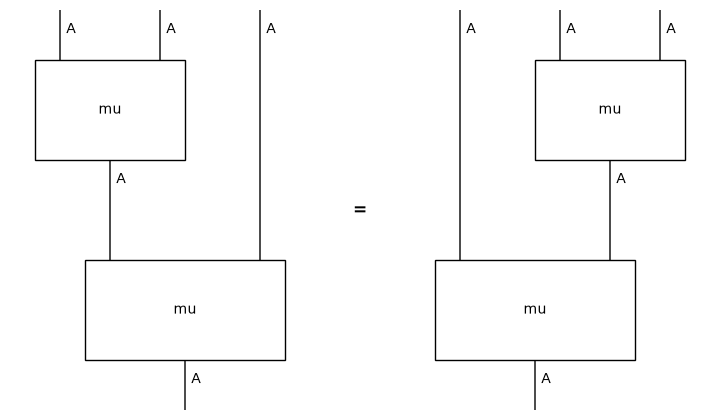

In [3]:
left = (mu @ I) >> mu
right = (I @ mu) >> mu
Equation(left, right).draw(figsize=(7, 4))
print('(3.6), left array:\n', F(left).array)
print('Right array:\n', F(right).array)
print('Exact model equality:', F(left) == F(right))
print('Free syntax equality:', left == right)

(3.8) left unit computed:
 [[1 0]
 [0 1]]
Expected identity:
 [[1 0]
 [0 1]] 
Match: True
(3.8) right unit computed:
 [[1 0]
 [0 1]]
Expected identity:
 [[1 0]
 [0 1]] 
Match: True


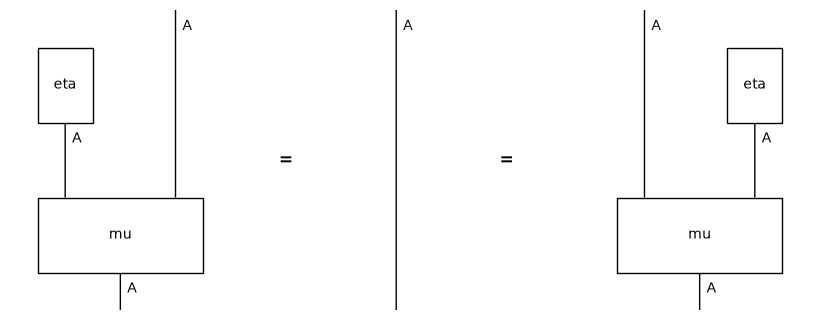

In [4]:
for label, side in [('left unit', (eta @ I) >> mu), ('right unit', (I @ eta) >> mu)]:
    print('(3.8)', label, 'computed:\n', F(side).array)
    print('Expected identity:\n', F(I).array, '\nMatch:', F(side) == F(I))
Equation((eta @ I) >> mu, I, (I @ eta) >> mu).draw(figsize=(8, 3))

The empty input of `eta` implements the invisible field wire in (3.25)–(3.26). The model check does not prove the algebra axioms for arbitrary multiplication data.